# Phase 9 – Feed-forward neural network (MLP), validation only

**Follows:** `08_final_evaluation.ipynb`. The four main models were tested on 2019 there, once.

**Why an MLP:** the project has a linear model, two tree ensembles and an attention model (FT-Transformer). A plain feed-forward network fills the gap between logistic regression and the FT-Transformer. It answers one question: **does attention help, or does any neural network land in the same place?** It is also the standard baseline in the FT-Transformer paper (Gorishniy et al., 2021).

**Validation only.** This model was added after the 2019 test year was scored. Scoring it on test now would be a second look at test after seeing the other results, so **it is never scored on test**. All numbers here are 2018 validation, and are compared with the other models' validation numbers.

**Same protocol as the other models:**
- Same chronological split, the same 30 selected features (variant A), the 2010+ training window and fraud:non-fraud sampling used by the FT-Transformer.
- Same preprocessing as the FT-Transformer (quantile transform, missing-value indicators, one learned vector per category level) and the same training loop (`fit_ft` with `model_fn=MLP`). Only the network differs.
- Tuned on **A**, then refit on **B** (no direct geography) with the settings frozen, as notebook 07 did for the other four.
- Same evaluation (`src/evaluation.py`): PR-AUC headline, threshold chosen on validation by max F1.

### Resuming after an interruption

Like notebook 06, **re-run from the top** after a power cut or freeze and it continues where it stopped:
- Every training run checkpoints to `models/checkpoints/mlp/` after each epoch and resumes from there. A finished run loads without retraining.
- The Optuna study lives in `models/optuna_mlp.db` (SQLite). A trial killed mid-run is re-queued with the same settings and resumes from its checkpoint. The 2-hour budget counts time already spent.
- Progress is appended to `models/mlp_run.log`.

To start fresh, delete `models/checkpoints/mlp/` and `models/optuna_mlp.db`.

## 0. Setup

In [1]:
import sys, json, time, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
import torch
from scipy.stats import spearmanr
from sklearn.metrics import average_precision_score

from src.data import PROJECT_ROOT
from src.modeling import TARGET, load_split, feature_sets, undersample
from src.evaluation import evaluate, compare, plot_pr_curves
from src.ft_transformer import TabularPreprocessor, to_device, predict, checkpoint_name
from src.mlp import fit_mlp
from src import final_models as fm

sns.set_style("whitegrid")
optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)   # heartbeat API
SEED = 0
MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "reports"
CACHE = PROJECT_ROOT / "data" / "cache"
CKPT_DIR = MODELS_DIR / "checkpoints" / "mlp"; CKPT_DIR.mkdir(parents=True, exist_ok=True)
LOG = MODELS_DIR / "mlp_run.log"

def log(msg):
    line = f"{time.strftime('%Y-%m-%d %H:%M:%S')}  {msg}"
    print(line)
    with open(LOG, "a", encoding="utf-8") as f:
        f.write(line + "\n")

print(torch.__version__, torch.cuda.get_device_name(0))

VARIANTS = json.loads((REPORTS_DIR / "feature_variants.json").read_text())["variants"]
FEATURES = feature_sets()["selected"]
assert sorted(FEATURES) == sorted(VARIANTS["A"])
assert set(VARIANTS["B"]) <= set(FEATURES)
train = load_split("train", FEATURES + ["year"])
val = load_split("val", FEATURES)
y_val = val[TARGET].to_numpy()
print(f"{len(FEATURES)} features | train {len(train):,} rows | val {len(val):,} rows, {y_val.sum():,} frauds")

C:\Users\001\.conda\envs\fraud-detection\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2.11.0+cu128 NVIDIA GeForce RTX 3060


30 features | train 20,604,847 rows | val 1,721,615 rows, 2,491 frauds


In [2]:
# Same window as CatBoost and the FT-Transformer (2010+). The sampling ratio is tuned below.
START_YEAR = 2010
recent = train[train["year"] >= START_YEAR]

_cache = {}
def prepare(neg_per_pos, seed=SEED):
    """Undersample, fit the preprocessor on that sample only, move train + val tensors to the GPU."""
    key = (neg_per_pos, seed)
    if key not in _cache:
        _cache.clear(); torch.cuda.empty_cache()
        s = undersample(recent, neg_per_pos, seed=seed)
        pre = TabularPreprocessor(FEATURES, seed=seed).fit(s)
        tr = to_device(*pre.transform(s), s[TARGET])
        va = to_device(*pre.transform(val), y_val)
        _cache[key] = (pre, tr, va)
    return _cache[key]

pre, tr, va = prepare(100)
print(f"{len(tr[2]):,} training rows | MLP input: {pre.n_num} numeric columns + {len(pre.cardinalities)} category embeddings")
results, val_scores = {}, {}

1,556,208 training rows | MLP input: 31 numeric columns + 3 category embeddings


## 1. The training recipe, fixed before any run

Notebook 06 showed that picking the best epoch on validation overstated the FT-Transformer by about 0.2 PR-AUC, because its validation curve jumped from epoch to epoch. This notebook therefore uses the stabilised recipe **everywhere, including inside the search**:
- linear warm-up for 1 epoch, then cosine decay of the learning rate to 0 over a **fixed 20 epochs**;
- an exponential moving average of the weights (decay 0.9995); the averaged model is the one evaluated;
- **no best-epoch selection**: the model after the last epoch is the model. Validation is recorded every epoch only for plots and for pruning.

So each trial's score is a last-epoch score, the same kind of number as the final result.

**Baseline:** a common default MLP: 3 blocks of 256 units, dropout 0.1, embeddings of size 16, AdamW (lr 1e-3, weight decay 1e-5), batch 1024, 1 fraud : 100 non-frauds.

In [3]:
STABLE = dict(epochs=20, schedule="cosine", warmup_epochs=1, ema_decay=0.9995, select_best=False)
BASE = dict(neg_per_pos=100, d_embedding=16, d_hidden=256, n_blocks=3, dropout=0.1,
            lr=1e-3, weight_decay=1e-5, batch_size=1024)

def train_config(cfg, seed=SEED, tag="run", on_epoch=None, verbose=True):
    pre, tr, va = prepare(cfg["neg_per_pos"])
    fit_kw = {k: v for k, v in cfg.items() if k != "neg_per_pos"}
    ckpt = CKPT_DIR / checkpoint_name(tag, {**cfg, **STABLE, "seed": seed})
    m, h = fit_mlp(tr, pre.n_num, pre.cardinalities, va, seed=seed, verbose=verbose,
                   on_epoch=on_epoch, checkpoint=ckpt, **STABLE, **fit_kw)
    return m, h, ckpt

t0 = time.time()
mlp_base, hist_base, _ = train_config(BASE, tag="baseline")
val_scores["MLP (baseline)"] = predict(mlp_base, va[0], va[1])
results["MLP (baseline)"] = evaluate(y_val, val_scores["MLP (baseline)"])
log(f"baseline: last-epoch val PR-AUC {results['MLP (baseline)']['pr_auc']:.4f} ({time.time() - t0:.0f}s, "
    f"{np.mean([r['secs'] for r in hist_base]):.1f}s/epoch)")
compare(results)

  epoch 1 | train_loss 0.0591 | secs 9.0738 | val_pr_auc 0.1593


  epoch 2 | train_loss 0.0099 | secs 7.8831 | val_pr_auc 0.1962


  epoch 3 | train_loss 0.0088 | secs 8.0451 | val_pr_auc 0.2519


  epoch 4 | train_loss 0.0082 | secs 7.9984 | val_pr_auc 0.2935


  epoch 5 | train_loss 0.0078 | secs 8.0828 | val_pr_auc 0.3366


  epoch 6 | train_loss 0.0075 | secs 7.7826 | val_pr_auc 0.3608


... (12 outputs left out)

  epoch 19 | train_loss 0.0048 | secs 4.1772 | val_pr_auc 0.4062


  epoch 20 | train_loss 0.0048 | secs 3.7042 | val_pr_auc 0.4045


2026-11-27 18:01:02  baseline: last-epoch val PR-AUC 0.4045 (169s, 7.8s/epoch)


,pr_auc,roc_auc,recall@precision0.5,precision@top0.1%,recall@top0.1%,threshold,precision@threshold,recall@threshold,alerts@threshold
MLP (baseline),0.4045,0.98,0.3978,0.5389,0.3725,0.5718,0.5088,0.395,1934.0


## 2. Tuning with Optuna (2-hour budget)

The search covers width, depth, dropout, embedding size, optimiser settings and the sampling ratio. It starts from the baseline (enqueued as trial 0), so it can only match or improve on it. Every trial trains the full fixed recipe above and is scored on its **last** epoch. A median pruner stops a trial that is below the median of earlier trials at the same epoch, after an 8-epoch warm-up.

In [4]:
TIME_BUDGET_H = 2
N_TRIALS = 120

def objective(trial):
    cfg = dict(
        neg_per_pos=trial.suggest_categorical("neg_per_pos", [40, 100, 200]),
        d_embedding=trial.suggest_categorical("d_embedding", [8, 16, 32]),
        d_hidden=trial.suggest_categorical("d_hidden", [128, 256, 512, 1024]),
        n_blocks=trial.suggest_int("n_blocks", 1, 5),
        dropout=trial.suggest_float("dropout", 0.0, 0.5),
        lr=trial.suggest_float("lr", 1e-4, 3e-3, log=True),
        weight_decay=trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
        batch_size=trial.suggest_categorical("batch_size", [512, 1024, 2048]),
    )
    holder = {}
    def report(epoch, ap):
        trial.report(ap, epoch)
        if trial.should_prune():
            holder["ckpt"].unlink(missing_ok=True)
            log(f"trial {trial.number}: pruned at epoch {epoch} (PR-AUC {ap:.4f})  {trial.params}")
            raise optuna.TrialPruned()
    pre, tr, va = prepare(cfg["neg_per_pos"])
    holder["ckpt"] = CKPT_DIR / checkpoint_name("trial", {**cfg, **STABLE, "seed": SEED})
    model, hist, ckpt = train_config(cfg, tag="trial", on_epoch=report, verbose=False)
    trial.set_user_attr("minutes", sum(r["secs"] for r in hist) / 60)
    trial.set_user_attr("peak_epoch", int(np.argmax([r["val_pr_auc"] for r in hist])) + 1)
    trial.set_user_attr("peak_pr_auc", max(r["val_pr_auc"] for r in hist))
    last = hist[-1]["val_pr_auc"]
    log(f"trial {trial.number}: last-epoch PR-AUC {last:.4f}  {trial.params}")
    del model; torch.cuda.empty_cache()
    ckpt.unlink(missing_ok=True)          # the result is now in the study database
    return last

storage = optuna.storages.RDBStorage(
    f"sqlite:///{(MODELS_DIR / 'optuna_mlp.db').as_posix()}",
    heartbeat_interval=60, grace_period=180,
    heartbeat_stale_trial_callback=optuna.storages.RetryHeartbeatStaleTrialCallback(max_retry=3))
study = optuna.create_study(study_name="mlp", storage=storage, load_if_exists=True, direction="maximize",
                            sampler=optuna.samplers.TPESampler(seed=SEED),
                            pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=8))
study.enqueue_trial(BASE, skip_if_exists=True)

done = [t for t in study.trials if t.state.name in ("COMPLETE", "PRUNED")]
spent_s = sum((t.datetime_complete - t.datetime_start).total_seconds() for t in done if t.datetime_start)
remaining_s = TIME_BUDGET_H * 3600 - spent_s
log(f"study: {len(done)} trials done, {spent_s / 3600:.2f} h spent, {max(remaining_s, 0) / 3600:.2f} h left")
if remaining_s > 0 and len(done) < N_TRIALS:
    study.optimize(objective, n_trials=N_TRIALS - len(done), timeout=remaining_s,
                   catch=(torch.OutOfMemoryError,))
best = dict(study.best_params)
log(f"study finished: {len(study.trials)} trials | best last-epoch val PR-AUC {study.best_value:.4f} | {best}")
best

2026-11-27 18:01:05  study: 0 trials done, 0.00 h spent, 2.00 h left


2026-11-27 18:04:05  trial 0: last-epoch PR-AUC 0.4045  {'neg_per_pos': 100, 'd_embedding': 16, 'd_hidden': 256, 'n_blocks': 3, 'dropout': 0.1, 'lr': 0.001, 'weight_decay': 1e-05, 'batch_size': 1024}


2026-11-27 18:06:32  trial 1: last-epoch PR-AUC 0.4223  {'neg_per_pos': 100, 'd_embedding': 32, 'd_hidden': 512, 'n_blocks': 4, 'dropout': 0.26444745987645224, 'lr': 0.0006903521707993515, 'weight_decay': 0.0005981221901152554, 'batch_size': 1024}


2026-11-27 18:13:12  trial 2: last-epoch PR-AUC 0.3902  {'neg_per_pos': 200, 'd_embedding': 8, 'd_hidden': 128, 'n_blocks': 5, 'dropout': 0.26092416087503584, 'lr': 0.00040973773756855373, 'weight_decay': 6.218230782016855e-06, 'batch_size': 512}


2026-11-27 18:14:16  trial 3: last-epoch PR-AUC 0.2758  {'neg_per_pos': 100, 'd_embedding': 16, 'd_hidden': 512, 'n_blocks': 4, 'dropout': 0.3353189348090797, 'lr': 0.00020453166444527109, 'weight_decay': 2.4365700014641986e-06, 'batch_size': 2048}


2026-11-27 18:15:22  trial 4: last-epoch PR-AUC 0.1794  {'neg_per_pos': 100, 'd_embedding': 32, 'd_hidden': 256, 'n_blocks': 1, 'dropout': 0.3281647947326367, 'lr': 0.0001599974181122749, 'weight_decay': 3.888186473153664e-06, 'batch_size': 1024}


... (112 outputs left out)

2026-11-27 19:49:43  trial 117: last-epoch PR-AUC 0.4271  {'neg_per_pos': 100, 'd_embedding': 32, 'd_hidden': 512, 'n_blocks': 2, 'dropout': 0.05542657629134078, 'lr': 0.0022784715001745674, 'weight_decay': 0.0005983181645870981, 'batch_size': 1024}


2026-11-27 19:50:58  trial 118: last-epoch PR-AUC 0.4400  {'neg_per_pos': 100, 'd_embedding': 32, 'd_hidden': 512, 'n_blocks': 2, 'dropout': 0.162610036957855, 'lr': 0.0020445485666271625, 'weight_decay': 0.0006285220046324366, 'batch_size': 1024}


2026-11-27 19:51:27  trial 119: pruned at epoch 8 (PR-AUC 0.4534)  {'neg_per_pos': 100, 'd_embedding': 32, 'd_hidden': 512, 'n_blocks': 2, 'dropout': 0.09245115738097241, 'lr': 0.0013193805012041624, 'weight_decay': 0.00035949735431299834, 'batch_size': 1024}
2026-11-27 19:51:27  study finished: 120 trials | best last-epoch val PR-AUC 0.4629 | {'neg_per_pos': 100, 'd_embedding': 32, 'd_hidden': 512, 'n_blocks': 2, 'dropout': 0.14879084770993906, 'lr': 0.0016966386436898567, 'weight_decay': 0.0001681743795480901, 'batch_size': 1024}


{'neg_per_pos': 100,
 'd_embedding': 32,
 'd_hidden': 512,
 'n_blocks': 2,
 'dropout': 0.14879084770993906,
 'lr': 0.0016966386436898567,
 'weight_decay': 0.0001681743795480901,
 'batch_size': 1024}

In [5]:
trials = study.trials_dataframe()
print(trials["state"].value_counts().to_dict())
cols = ["number", "value", "user_attrs_peak_pr_auc", "user_attrs_peak_epoch", "user_attrs_minutes"] + \
       [c for c in trials.columns if c.startswith("params_")]
trials[cols].sort_values("value", ascending=False).head(10)

{'PRUNED': 66, 'COMPLETE': 54}


,number,value,user_attrs_peak_pr_auc,user_attrs_peak_epoch,user_attrs_minutes,params_batch_size,params_d_embedding,params_d_hidden,params_dropout,params_lr,params_n_blocks,params_neg_per_pos,params_weight_decay
116,116,0.473684,NaN,NaN,NaN,1024,32,512,0.159732,0.001882,2,100,0.000167
97,97,0.471663,NaN,NaN,NaN,1024,32,512,0.207052,0.002223,2,100,0.000914
102,102,0.470788,NaN,NaN,NaN,1024,32,512,0.154447,0.002917,2,100,0.000091
75,75,0.467907,NaN,NaN,NaN,1024,32,512,0.171719,0.002667,2,100,0.000253
88,88,0.467712,NaN,NaN,NaN,1024,32,512,0.054507,0.001716,2,100,0.000187
67,67,0.466870,NaN,NaN,NaN,1024,32,512,0.133235,0.002187,2,100,0.000297
109,109,0.464217,NaN,NaN,NaN,1024,32,512,0.067044,0.002701,2,100,0.000165
113,113,0.462914,0.482991,10.0,1.107737,1024,32,512,0.148791,0.001697,2,100,0.000168
105,105,0.462394,NaN,NaN,NaN,1024,32,512,0.205482,0.001377,2,100,0.000231
103,103,0.461844,NaN,NaN,NaN,1024,32,512,0.127498,0.001773,2,100,0.000074


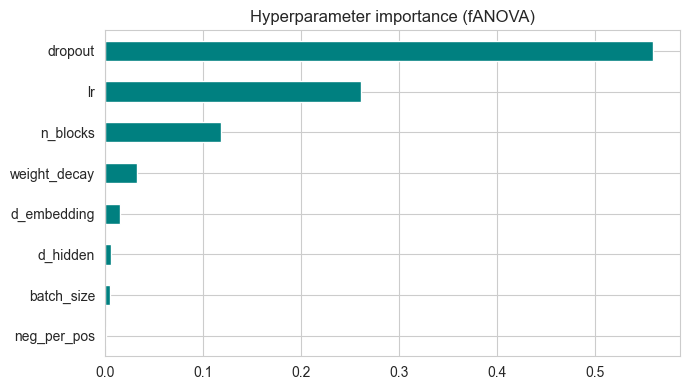

In [6]:
if sum(t.state.name == "COMPLETE" for t in study.trials) >= 4:   # fANOVA uses completed trials only
    imp = pd.Series(optuna.importance.get_param_importances(
        study, evaluator=optuna.importance.FanovaImportanceEvaluator(seed=SEED)))
    imp.sort_values().plot(kind="barh", figsize=(7, 4), color="teal")
    plt.title("Hyperparameter importance (fANOVA)")
    plt.tight_layout(); plt.show()

## 3. Final tuned model: 3 seeds, averaged

As for the FT-Transformer: the best settings, trained with seeds 0, 1 and 2 (initialisation and batch order; same training sample and preprocessor). Each seed is reported, and the final "tuned" score is the **average of the three seeds' probabilities**.

Seed 0 with the best settings is the same run as the best trial, so it repeats that trial's score. The search picked the best of many trials, so that one number is a little optimistic. Seeds 1 and 2 are fresh runs, so the 3-seed average is a fairer estimate.

In [7]:
SEEDS = [0, 1, 2]
pre, tr, va = prepare(best["neg_per_pos"])
mlp_seeds, hist_seeds, seed_scores = [], {}, {}
for s in SEEDS:
    t0 = time.time()
    m, h, _ = train_config(best, seed=s, tag="final")
    mlp_seeds.append(m); hist_seeds[s] = h
    seed_scores[s] = predict(m, va[0], va[1])
    log(f"final seed {s}: last-epoch val PR-AUC {h[-1]['val_pr_auc']:.4f}  ({time.time() - t0:.0f}s)")

seed_ap = pd.Series({s: average_precision_score(y_val, p) for s, p in seed_scores.items()}, name="val_pr_auc")
print(f"single seeds: {seed_ap.round(4).to_dict()} | mean {seed_ap.mean():.4f} ± {seed_ap.std():.4f} (std)")
val_scores["MLP (tuned)"] = np.mean([seed_scores[s] for s in SEEDS], axis=0)
results["MLP (tuned)"] = evaluate(y_val, val_scores["MLP (tuned)"])
log(f"final 3-seed average (A): val PR-AUC {results['MLP (tuned)']['pr_auc']:.4f}")
compare(results)

  epoch 1 | train_loss 0.0394 | secs 3.1396 | val_pr_auc 0.1761


  epoch 2 | train_loss 0.0092 | secs 3.0736 | val_pr_auc 0.2577


  epoch 3 | train_loss 0.0083 | secs 3.0695 | val_pr_auc 0.3043


  epoch 4 | train_loss 0.0080 | secs 3.1567 | val_pr_auc 0.3694


  epoch 5 | train_loss 0.0077 | secs 3.2096 | val_pr_auc 0.4180


  epoch 6 | train_loss 0.0074 | secs 3.2211 | val_pr_auc 0.4567


... (53 outputs left out)

  epoch 20 | train_loss 0.0043 | secs 3.0467 | val_pr_auc 0.4319
2026-11-27 19:55:04  final seed 2: last-epoch val PR-AUC 0.4319  (75s)


single seeds: {0: 0.4629, 1: 0.4419, 2: 0.4319} | mean 0.4456 ± 0.0159 (std)


2026-11-27 19:55:05  final 3-seed average (A): val PR-AUC 0.4554


,pr_auc,roc_auc,recall@precision0.5,precision@top0.1%,recall@top0.1%,threshold,precision@threshold,recall@threshold,alerts@threshold
MLP (baseline),0.4045,0.9800,0.3978,0.5389,0.3725,0.5718,0.5088,0.3950,1934.0
MLP (tuned),0.4554,0.9833,0.4408,0.5796,0.4006,0.6185,0.5784,0.4026,1734.0


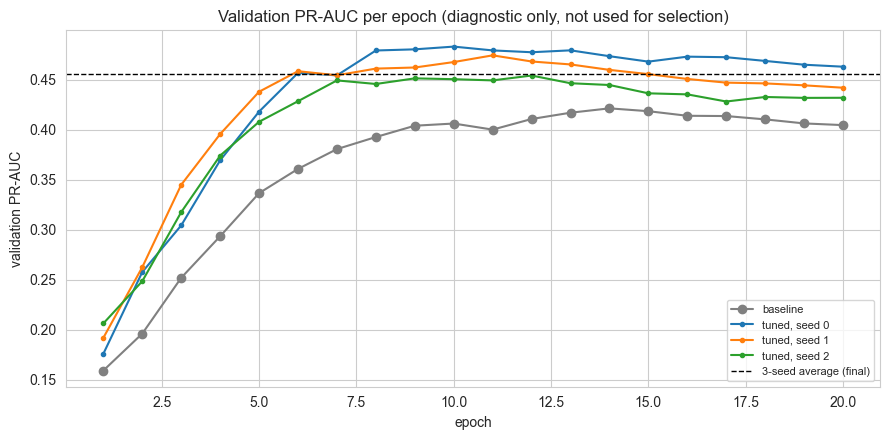

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.5))
hb = pd.DataFrame(hist_base)
ax.plot(hb["epoch"], hb["val_pr_auc"], marker="o", color="grey", label="baseline")
for s, h in hist_seeds.items():
    h = pd.DataFrame(h)
    ax.plot(h["epoch"], h["val_pr_auc"], marker=".", label=f"tuned, seed {s}")
ax.axhline(results["MLP (tuned)"]["pr_auc"], ls="--", color="black", lw=1, label="3-seed average (final)")
ax.set(xlabel="epoch", ylabel="validation PR-AUC", title="Validation PR-AUC per epoch (diagnostic only, not used for selection)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 4. Save the tuned model, then refit on variant B

The settings are written to `reports/best_params_mlp.json` first. `src/final_models.py` then refits the MLP on variant B (no `is_international`, no `zip_freq`) with those settings frozen, exactly as notebook 07 did for the other four models.

In [9]:
PARAMS = {**best, **STABLE}
torch.save({"state_dicts": [m.state_dict() for m in mlp_seeds],
            "params": {**PARAMS, "seeds": SEEDS}, "preprocessor": pre},
           MODELS_DIR / "mlp_tuned.pt")
(REPORTS_DIR / "best_params_mlp.json").write_text(json.dumps(
    {"mlp": {"params": PARAMS, "seeds": SEEDS, "start_year": START_YEAR,
             "val_pr_auc_per_seed": seed_ap.round(4).to_dict(),
             "val_threshold": results["MLP (tuned)"]["threshold"],
             "note": "validation only: added after the 2019 test year was scored, never scored on test"}},
    indent=2, default=str))
trials[cols].to_csv(REPORTS_DIR / "optuna_trials_mlp.csv", index=False)
del mlp_seeds; _cache.clear(); torch.cuda.empty_cache()

params = fm.load_params()
bundle_b = fm.load_bundle("MLP", "B")
if bundle_b is None:
    t0 = time.time()
    bundle_b = fm.fit("MLP", train, VARIANTS["B"], params, ckpt_dir=CKPT_DIR, tag="variant_B", val=val)
    fm.save_bundle(bundle_b, "MLP", "B")
    log(f"MLP B: fitted in {time.time() - t0:.0f}s")
val_scores["MLP B"] = fm.score(bundle_b, val)
results["MLP B"] = evaluate(y_val, val_scores["MLP B"])
log(f"MLP B: val PR-AUC {results['MLP B']['pr_auc']:.4f}")

# Check: the frozen recipe reproduces the notebook's own A model
bundle_a = fm.fit("MLP", train, FEATURES, params, ckpt_dir=CKPT_DIR, tag="variant_A_check", val=val, verbose=False)
diff = np.abs(fm.score(bundle_a, val) - val_scores["MLP (tuned)"]).max()
print(f"reproduction check, src/final_models.py A vs this notebook: max |diff| = {diff:.2e}")
del bundle_a; torch.cuda.empty_cache()
compare(results)

  epoch 1 | train_loss 0.0419 | secs 3.5603 | val_pr_auc 0.0676


  epoch 2 | train_loss 0.0097 | secs 3.1696 | val_pr_auc 0.0980


  epoch 3 | train_loss 0.0087 | secs 3.1707 | val_pr_auc 0.1133


  epoch 4 | train_loss 0.0084 | secs 3.7663 | val_pr_auc 0.1263


  epoch 5 | train_loss 0.0082 | secs 4.1678 | val_pr_auc 0.1368


  epoch 6 | train_loss 0.0079 | secs 3.7058 | val_pr_auc 0.1388


... (53 outputs left out)

  epoch 20 | train_loss 0.0048 | secs 3.1096 | val_pr_auc 0.1597
2026-11-27 19:58:54  MLP B: fitted in 229s


2026-11-27 19:58:59  MLP B: val PR-AUC 0.1614


reproduction check, src/final_models.py A vs this notebook: max |diff| = 0.00e+00


,pr_auc,roc_auc,recall@precision0.5,precision@top0.1%,recall@top0.1%,threshold,precision@threshold,recall@threshold,alerts@threshold
MLP (baseline),0.4045,0.9800,0.3978,0.5389,0.3725,0.5718,0.5088,0.3950,1934.0
MLP (tuned),0.4554,0.9833,0.4408,0.5796,0.4006,0.6185,0.5784,0.4026,1734.0
MLP B,0.1614,0.9139,0.1072,0.2700,0.1867,0.4588,0.2837,0.1819,1597.0


## 5. Comparison with the other models (validation 2018)

The other models' validation numbers come from notebooks 04-07. They are the tuned models on A and the frozen refits on B, the same protocol as here.

In [10]:
val_a = pd.concat([
    pd.read_csv(REPORTS_DIR / "val_metrics_traditional.csv", index_col=0).loc[["LogReg (tuned)", "RandomForest (tuned)"]],
    pd.read_csv(REPORTS_DIR / "val_metrics_catboost.csv", index_col=0).loc[["CatBoost (tuned)"]],
    pd.read_csv(REPORTS_DIR / "val_metrics_ft_transformer.csv", index_col=0).loc[["FT-Transformer (tuned)"]],
    compare(results).loc[["MLP (tuned)"]]])
val_a.index = [i.replace(" (tuned)", "") for i in val_a.index]
val_b = pd.concat([pd.read_csv(REPORTS_DIR / "val_metrics_variant_B.csv", index_col=0), compare(results).loc[["MLP B"]]])
val_b.index = [i.replace(" B", "") for i in val_b.index]
table = pd.DataFrame({"val PR-AUC A": val_a["pr_auc"], "val PR-AUC B": val_b["pr_auc"],
                      "recall@P0.5 B": val_b["recall@precision0.5"], "alerts@thr B": val_b["alerts@threshold"]})
table["A - B"] = table["val PR-AUC A"] - table["val PR-AUC B"]
table.round(4)

,val PR-AUC A,val PR-AUC B,recall@P0.5 B,alerts@thr B,A - B
LogReg,0.1521,0.0196,0.0000,6156.0,0.1325
RandomForest,0.7155,0.4827,0.5608,2817.0,0.2328
CatBoost,0.8636,0.4802,0.4789,2146.0,0.3834
FT-Transformer,0.5328,0.4237,0.4018,1772.0,0.1091
MLP,0.4554,0.1614,0.1072,1597.0,0.2940


C:\Users\001\AppData\Local\Temp\ipykernel_15128\742513973.py:12: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout(); plt.show()


C:\Users\001\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


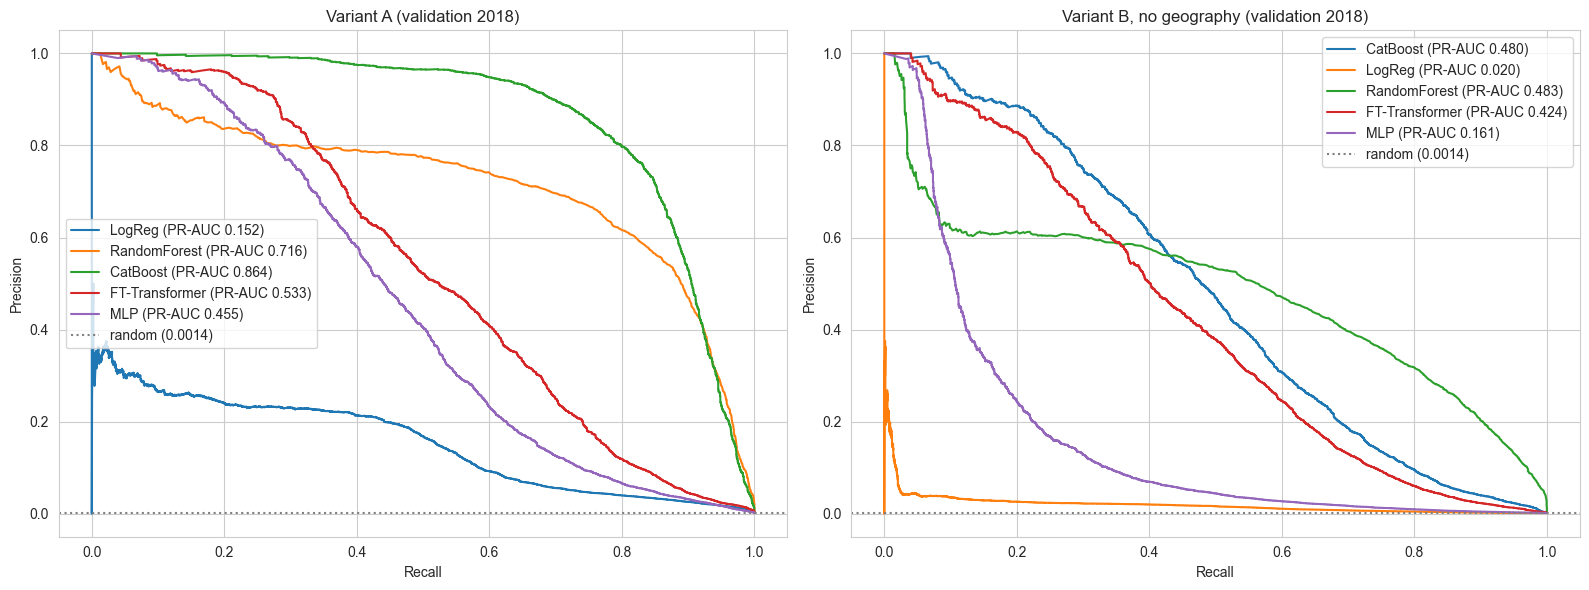

In [11]:
cb = pd.read_parquet(CACHE / "val_scores_catboost.parquet")["CatBoost (tuned)"].to_numpy()
ft = pd.read_parquet(CACHE / "val_scores_ft_transformer.parquet")["FT-Transformer (tuned)"].to_numpy()
trad = pd.read_parquet(CACHE / "val_scores_traditional.parquet")
scores_a = {"LogReg": trad["LogReg (tuned)"].to_numpy(), "RandomForest": trad["RandomForest (tuned)"].to_numpy(),
            "CatBoost": cb, "FT-Transformer": ft, "MLP": val_scores["MLP (tuned)"]}
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
plot_pr_curves(y_val, scores_a, ax=axes[0], title="Variant A (validation 2018)")
abl = pd.read_parquet(CACHE / "val_scores_ablation.parquet")
scores_b = {k.replace(" B", ""): abl[k].to_numpy() for k in abl.columns if k.endswith(" B")}
scores_b["MLP"] = val_scores["MLP B"]
plot_pr_curves(y_val, scores_b, ax=axes[1], title="Variant B, no geography (validation 2018)")
plt.tight_layout(); plt.show()

### Does the MLP rank transactions like the FT-Transformer?

If the two neural networks agree closely, attention adds little beyond what a plain network already learns from the same inputs.

In [12]:
fraud = y_val == 1
for name, other in [("FT-Transformer", ft), ("CatBoost", cb)]:
    print(f"MLP vs {name:15s} Spearman, all: {spearmanr(val_scores['MLP (tuned)'], other)[0]:.3f} | "
          f"frauds only: {spearmanr(val_scores['MLP (tuned)'][fraud], other[fraud])[0]:.3f}")

MLP vs FT-Transformer  Spearman, all: 0.667 | frauds only: 0.705


MLP vs CatBoost        Spearman, all: 0.413 | frauds only: 0.790


## 6. Save

In [13]:
compare(results).to_csv(REPORTS_DIR / "val_metrics_mlp.csv")
pd.DataFrame({"MLP A": val_scores["MLP (tuned)"], "MLP B": val_scores["MLP B"]}).astype("float32") \
    .to_parquet(CACHE / "val_scores_mlp.parquet")
print("Saved: models/mlp_tuned.pt, models/final/mlp_B.joblib, reports/{val_metrics_mlp.csv, best_params_mlp.json, "
      "optuna_trials_mlp.csv}, data/cache/val_scores_mlp.parquet")

Saved: models/mlp_tuned.pt, models/final/mlp_B.joblib, reports/{val_metrics_mlp.csv, best_params_mlp.json, optuna_trials_mlp.csv}, data/cache/val_scores_mlp.parquet


### Findings

All numbers are 2018 validation. The MLP was never scored on the 2019 test year.

**The MLP is fourth on both variants, below the FT-Transformer.** The final model (3 seeds averaged) reaches val PR-AUC **0.455 on A** and **0.161 on B**. That compares with 0.533 / 0.424 for the FT-Transformer, 0.864 / 0.480 for CatBoost and 0.716 / 0.483 for the Random Forest. Only logistic regression is lower (0.152 / 0.020).

**Removing geography hurts the MLP far more than the FT-Transformer.** On A the gap between the two networks is 0.08. On B it is 0.26: the FT-Transformer keeps 80% of its A score, the MLP keeps 35%. With `is_international` and `zip_freq` available, a plain network can lean on them. Without them, the remaining signal is likely in interactions between features (channel × new merchant × amount vs the card's history), which is also why logistic regression collapses on B. The FT-Transformer, with one token per feature and attention between them, does much better there than one stacked input vector. So for this data **the FT-Transformer's architecture does help, and the help is in the hard, geography-free part of the problem.** This comparison can't say whether the feature tokens or the attention matter more; both differ between the two models.

**The search was thorough and honest, and the numbers are stable.**
- 120 trials in 1 h 50 min (54 completed, 66 pruned), every one trained with the final recipe (cosine lr + EMA, fixed 20 epochs, last epoch scored). So the trial scores are the same kind of number as the final one, unlike notebook 06's best-epoch search.
- Tuning improved A from 0.405 (baseline) to 0.455. The search settled on 2 blocks of 512 units, embeddings of 32, dropout 0.15, lr 1.7e-3 and 1:100 sampling, the same ratio every other model uses.
- Seeds score 0.463, 0.442 and 0.432. Seed 0 is the best trial itself, so it is the optimistic one, and the 3-seed average (0.455) is the number reported.
- The validation curves are smooth (no jumps like the FT-Transformer's constant-lr baseline). On B they peak around epochs 12–14 and then drift down slightly, the same mild overfitting to 2010–2017 seen in notebook 06. The epoch count was fixed before the run and was not changed after seeing this.
- `src/final_models.py` reproduces this notebook's A model exactly (max difference 0), so the B refit uses exactly the recipe that was tuned.

**The two networks rank frauds alike.** Spearman correlation with the FT-Transformer is 0.67 over all transactions and 0.71 over frauds. With CatBoost it is 0.41 overall but 0.79 over frauds: the models mostly agree on which frauds are easy, and differ on how they order ordinary transactions.

**Conclusion.** The ranking on this data is trees > FT-Transformer > MLP > logistic regression, on both feature sets. A plain feed-forward network is a reasonable model when the geography shortcut is available and a weak one when it isn't. The gap shows that the FT-Transformer's architecture, not just "being a neural network", is what makes it competitive here.

**Not done, on purpose:** no test-year score (the test year is spent), and no extra tuning on B (B uses A's frozen settings, like every other model).